# CardioIA — Fase 6: Modelo Preditivo de Pico de Risco

## 1. Objetivo

Treinar um classificador supervisionado que estima a probabilidade de **pico de risco** (`pico_risco`) a partir de 10 indicadores clínicos e operacionais. O modelo salvo aqui (`modelo_pico_risco.joblib` + metadados) é carregado pelo sistema multiagente (`src/main.py`): o Agente Analista de Risco o usa para calcular a probabilidade, e os demais agentes selecionam protocolos e redigem a recomendação.

> **Aviso.** A base é **sintética** (código fornecido no enunciado) e o sistema é **acadêmico e informativo**: não realiza diagnóstico, não prescreve tratamentos e não substitui um profissional de saúde.

O notebook é autocontido: roda no Google Colab ("Ambiente de execução › Executar tudo") sem depender do repositório.

## 2. Ambiente

As versões impressas abaixo são as do treino e coincidem com as do `requirements.txt` do projeto (o pickle do scikit-learn só é garantido na mesma versão).

In [1]:
import sys

import joblib
import matplotlib
import numpy as np
import pandas as pd
import sklearn

print("Python      :", sys.version)
print("scikit-learn:", sklearn.__version__)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("joblib      :", joblib.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
scikit-learn: 1.9.1
numpy       : 2.5.4
pandas      : 3.0.6
joblib      : 1.6.0
matplotlib  : 3.11.2


In [2]:
# Reinstala as versões do requirements.txt caso o runtime do Colab mude depois do treino.
# Descomente, execute e reinicie o runtime antes de "Executar tudo".
# !pip install scikit-learn==1.9.1 numpy==2.5.4 pandas==3.0.6 joblib==1.6.0 matplotlib==3.11.2

## 3. Geração da base sintética

Código literal do enunciado (semente 42, 5000 registros). `risk_score` é uma variável auxiliar: soma das 6 regras de limiar que definem o alvo. Ela **não** entra em `X`, para não vazar o alvo. O mesmo código está em `src/ml/dataset.py`.

In [3]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)

print("shape:", df.shape)
print("prevalência de pico_risco:", round(df["pico_risco"].mean(), 4))

shape: (5000, 11)
prevalência de pico_risco: 0.2658


## 4. Análise exploratória

Dimensões: (5000, 11)


,count,mean,std,min,25%,50%,75%,max
idade_media,5000.0,55.058872,11.925581,18.000000,47.105140,55.161587,62.992127,90.000000
carga_sistema,5000.0,64.637825,19.987923,30.003698,47.604462,64.430649,81.684947,99.977124
tempo_espera,5000.0,45.243077,19.383549,5.000000,31.838260,45.143356,58.278490,113.578210
fc_media,5000.0,85.305275,14.897908,50.000000,75.000614,85.218044,95.604945,150.000000
spo2_media,5000.0,94.920231,2.874954,83.430874,92.900337,94.984043,97.009198,100.000000
pa_sistolica,5000.0,124.893487,19.529416,80.000000,111.201401,125.058077,138.054290,198.832490
temperatura,5000.0,24.003366,5.080669,10.000000,20.514351,23.967477,27.506223,40.000000
densidade_eventos,5000.0,2.998000,1.731876,0.000000,2.000000,3.000000,4.000000,13.000000
eventos_24h,5000.0,1.992400,1.418430,0.000000,1.000000,2.000000,3.000000,9.000000
disponibilidade_recursos,5000.0,60.271841,23.030132,20.035489,40.186700,60.871675,80.393247,99.989376


Valores nulos por coluna:
idade_media                 0
carga_sistema               0
tempo_espera                0
fc_media                    0
spo2_media                  0
pa_sistolica                0
temperatura                 0
densidade_eventos           0
eventos_24h                 0
disponibilidade_recursos    0
pico_risco                  0
dtype: int64

Distribuição do alvo (proporção):
pico_risco
0    0.7342
1    0.2658
Name: proportion, dtype: float64


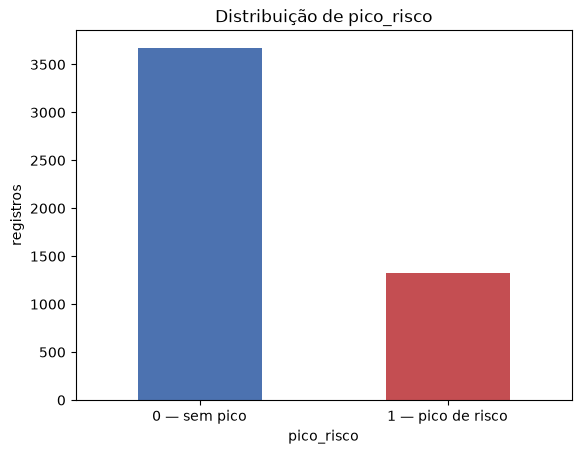

In [4]:
import matplotlib.pyplot as plt

print("Dimensões:", df.shape)
display(df.describe().T)
print("Valores nulos por coluna:")
print(df.isnull().sum())
print("\nDistribuição do alvo (proporção):")
print(df["pico_risco"].value_counts(normalize=True))

ax = df["pico_risco"].value_counts().sort_index().plot(kind="bar", color=["#4c72b0", "#c44e52"])
ax.set_xticklabels(["0 — sem pico", "1 — pico de risco"], rotation=0)
ax.set_ylabel("registros")
ax.set_title("Distribuição de pico_risco")
plt.show()

## 5. Preparação dos dados

Ordem canônica das features (a mesma de `src/domain/constantes.py`). Split 80/20 estratificado pelo alvo, para manter a proporção de positivos no treino e no teste.

In [5]:
from sklearn.model_selection import train_test_split

FEATURES = [
    "idade_media", "carga_sistema", "tempo_espera", "fc_media", "spo2_media",
    "pa_sistolica", "temperatura", "densidade_eventos", "eventos_24h",
    "disponibilidade_recursos",
]

X = df[FEATURES]
y = df["pico_risco"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

assert "risk_score" not in X.columns
assert list(X.columns) == FEATURES
assert abs(y_train.mean() - y_test.mean()) < 0.005
print("treino:", X_train.shape, "| teste:", X_test.shape)
print("prevalência treino:", round(y_train.mean(), 4), "| teste:", round(y_test.mean(), 4))

treino: (4000, 10) | teste: (1000, 10)
prevalência treino: 0.2658 | teste: 0.266


## 6–7. Modelos

| Modelo | Papel | Hiperparâmetros |
|---|---|---|
| Regressão Logística | baseline interpretável | `StandardScaler` + `LogisticRegression(max_iter=1000, random_state=42)` (o scaler fica dentro do `Pipeline`, ajustado só no treino) |
| Random Forest | modelo principal | `RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)` |

**Por que Random Forest.** O alvo é uma soma de indicadores de limiar (funções degrau): `pico_risco = 1` quando pelo menos 2 de 6 condições são verdadeiras. Uma fronteira linear não reproduz "≥ 2 de 6", então a Regressão Logística perde recall. Árvores aprendem cortes por limiar diretamente. Entre as árvores, o RF é melhor que uma árvore de decisão isolada porque a média de 200 árvores produz **probabilidades graduais**; uma árvore única devolve quase sempre 0 ou 1, o que esvaziaria as faixas de risco BAIXO/MODERADO/ALTO usadas pelo sistema multiagente.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

modelo_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
modelo_lr.fit(X_train, y_train)
print("Regressão Logística treinada.")

Regressão Logística treinada.


In [7]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
modelo_rf.fit(X_train, y_train)
print("Random Forest treinado.")

Random Forest treinado.


## 8. Avaliação no conjunto de teste

===== Regressão Logística =====
Acurácia: 0.816
              precision    recall  f1-score   support

           0     0.8490    0.9114    0.8791       734
           1     0.6934    0.5526    0.6151       266

    accuracy                         0.8160      1000
   macro avg     0.7712    0.7320    0.7471      1000
weighted avg     0.8076    0.8160    0.8089      1000

Matriz de confusão [[TN FP] [FN TP]]:
[[669  65]
 [119 147]]

===== Random Forest =====
Acurácia: 0.999
              precision    recall  f1-score   support

           0     0.9986    1.0000    0.9993       734
           1     1.0000    0.9962    0.9981       266

    accuracy                         0.9990      1000
   macro avg     0.9993    0.9981    0.9987      1000
weighted avg     0.9990    0.9990    0.9990      1000

Matriz de confusão [[TN FP] [FN TP]]:
[[734   0]
 [  1 265]]



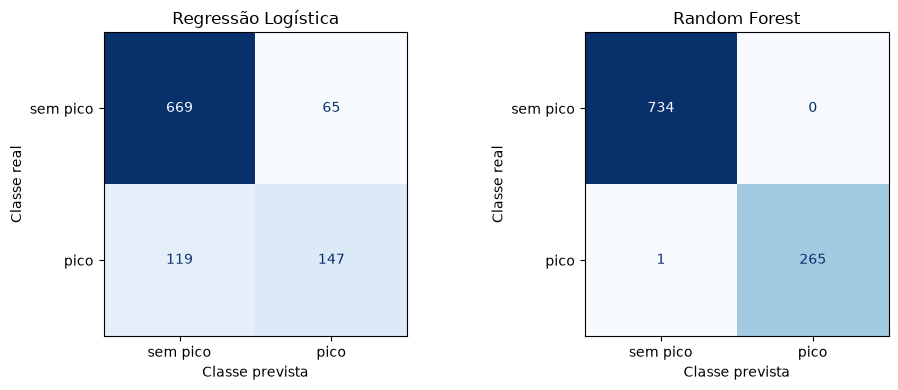

matriz_confusao_rf.png salva.


In [8]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
)

modelos = {"Regressão Logística": modelo_lr, "Random Forest": modelo_rf}
previsoes = {}
for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_test)
    previsoes[nome] = y_pred
    print(f"===== {nome} =====")
    print("Acurácia:", round(accuracy_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred, digits=4))
    print("Matriz de confusão [[TN FP] [FN TP]]:")
    print(confusion_matrix(y_test, y_pred))
    print()

fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for eixo, (nome, y_pred) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["sem pico", "pico"], cmap="Blues", ax=eixo, colorbar=False
    )
    eixo.set_title(nome)
    eixo.set_xlabel("Classe prevista")
    eixo.set_ylabel("Classe real")
plt.tight_layout()
plt.show()

# Figura isolada do modelo principal, usada no README e no relatório.
fig_rf, eixo_rf = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, previsoes["Random Forest"], display_labels=["sem pico", "pico"],
    cmap="Blues", ax=eixo_rf, colorbar=False,
)
eixo_rf.set_title("Random Forest — matriz de confusão (teste)")
eixo_rf.set_xlabel("Classe prevista")
eixo_rf.set_ylabel("Classe real")
fig_rf.tight_layout()
fig_rf.savefig("matriz_confusao_rf.png", dpi=150)
plt.close(fig_rf)
print("matriz_confusao_rf.png salva.")

## 9. Validação cruzada (treino)

`StratifiedKFold` com 5 dobras embaralhadas, apenas no conjunto de treino.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv = {}
for nome, modelo in modelos.items():
    notas = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="accuracy")
    resultados_cv[nome] = notas
    print(f"{nome}: {notas.mean():.4f} ± {notas.std():.4f}  (dobras: {np.round(notas, 4)})")

Regressão Logística: 0.8297 ± 0.0140  (dobras: [0.8175 0.825  0.8138 0.8438 0.8488])


Random Forest: 0.9977 ± 0.0018  (dobras: [0.9988 0.9988 0.9962 0.995  1.    ])


## 10. Tabela comparativa

In [10]:
tabela = pd.DataFrame([
    {
        "modelo": nome,
        "acuracia": accuracy_score(y_test, y_pred),
        "precisao_1": precision_score(y_test, y_pred),
        "recall_1": recall_score(y_test, y_pred),
        "f1_1": f1_score(y_test, y_pred),
        "acuracia_cv": f"{resultados_cv[nome].mean():.4f} ± {resultados_cv[nome].std():.4f}",
    }
    for nome, y_pred in previsoes.items()
]).set_index("modelo")
tabela.round(4)

,acuracia,precisao_1,recall_1,f1_1,acuracia_cv
modelo,,,,,
Regressão Logística,0.816,0.6934,0.5526,0.6151,0.8297 ± 0.0140
Random Forest,0.999,1.0000,0.9962,0.9981,0.9977 ± 0.0018


## 11. Importância das features (Random Forest)

carga_sistema               0.2330
disponibilidade_recursos    0.2242
tempo_espera                0.2020
spo2_media                  0.1660
fc_media                    0.0695
eventos_24h                 0.0641
idade_media                 0.0129
temperatura                 0.0119
pa_sistolica                0.0115
densidade_eventos           0.0050
dtype: float64


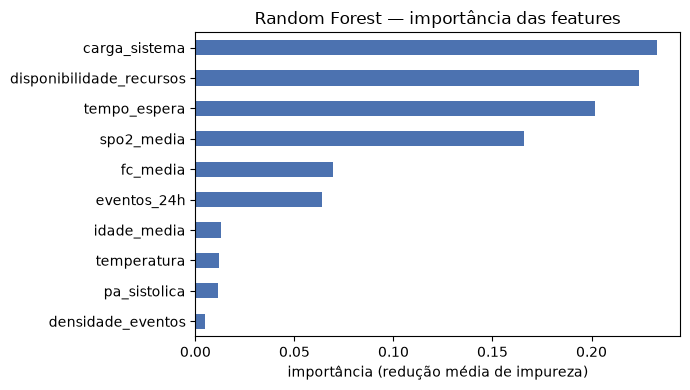

In [11]:
importancias = pd.Series(modelo_rf.feature_importances_, index=FEATURES).sort_values()
print(importancias.sort_values(ascending=False).round(4))

ax = importancias.plot(kind="barh", color="#4c72b0", figsize=(7, 4))
ax.set_xlabel("importância (redução média de impureza)")
ax.set_title("Random Forest — importância das features")
plt.tight_layout()
plt.show()

## 12. Interpretação dos resultados

**Números desta execução (conjunto de teste, 1000 registros):**

| Modelo | Acurácia | Precisão (1) | Recall (1) | F1 (1) | Acurácia CV (5-fold) | Matriz [TN FP / FN TP] |
|---|---:|---:|---:|---:|---:|---|
| Regressão Logística | 0,8160 | 0,6934 | 0,5526 | 0,6151 | 0,8297 ± 0,0140 | [669 65 / 119 147] |
| Random Forest | 0,9990 | 1,0000 | 0,9962 | 0,9981 | 0,9977 ± 0,0018 | [734 0 / 1 265] |

**Falso negativo × falso positivo.** Neste problema o erro grave é o **falso negativo**: um pico de risco real classificado como "sem pico" deixa a unidade sem preparação (sem abrir leitos, sem redistribuir insumos). O falso positivo custa recursos mobilizados à toa, mas é recuperável. A Regressão Logística erra 119 positivos (FN) e 65 negativos (FP); o Random Forest erra 1 FN e 0 FP. Por isso o recall da classe 1 é a métrica mais importante depois da acurácia, e o RF é o modelo escolhido.

**Por que a acurácia é ~100% (e por que isso não é vazamento).** O alvo `pico_risco` é uma função determinística das próprias features: vale 1 quando pelo menos 2 de 6 regras de limiar são verdadeiras (`carga_sistema > 80`, `tempo_espera > 60`, `spo2_media < 92`, `fc_media > 110`, `eventos_24h > 4`, `disponibilidade_recursos < 40`), sem nenhum ruído. As árvores reaprendem esses cortes. O split treino/teste é correto (estratificado, `risk_score` fora de `X`), então não há informação do teste no treino: a base é que é trivialmente separável. A evidência está nas importâncias: as 4 features que não entram na regra têm importância próxima de zero (`idade_media` = 0,0129, `pa_sistolica` = 0,0115, `temperatura` = 0,0119, `densidade_eventos` = 0,0050; soma 0,0413, contra 0,9587 das 6 features da regra). O pequeno valor residual vem de divisões aleatórias das árvores, não de sinal real. A LR fica em 0,816 porque uma fronteira linear não representa "pelo menos 2 de 6 condições".

**Limitações.**
- Dados sintéticos e sem ruído: a acurácia não indica desempenho em dados reais; a generalização não está comprovada.
- Desbalanceamento moderado: 26,6% de positivos (tratado com `stratify` no split e na CV).
- Semântica ambígua de `temperatura`: a média 24 sugere temperatura ambiente, mas o protocolo P07 fala em > 38 °C (febre).
- Os registros misturam indicadores do paciente (FC, SpO2, PA) e da unidade (carga, espera, recursos).
- Probabilidades do RF não são calibradas: servem para ordenar o risco e para as faixas BAIXO/MODERADO/ALTO, não como frequência exata.

**Melhorias.** Dados reais ou rotulados por especialistas; ruído e rótulos incertos na simulação; validação temporal; calibração de probabilidade (`CalibratedClassifierCV`); ajuste do limiar de decisão pelo custo do falso negativo; monitoramento de *drift* em produção.

## 13. Persistência do modelo e dos metadados

`n_jobs=1` antes de salvar: a predição de um paciente por vez fica mais rápida sem o custo de abrir processos. Os metadados registram features, limiar, métricas reais, faixas de treino (para avisos de extrapolação) e versões das bibliotecas.

In [12]:
import json
import os
import platform
from datetime import datetime, timezone

modelo_rf.set_params(n_jobs=1)
joblib.dump(modelo_rf, "modelo_pico_risco.joblib", compress=3)
tamanho_mb = os.path.getsize("modelo_pico_risco.joblib") / 1024**2
print(f"modelo_pico_risco.joblib: {tamanho_mb:.2f} MB")
assert tamanho_mb < 50, "Acima de 50 MB: reduzir n_estimators para 100 e registrar no relatório"


def metricas(y_true, y_pred):
    return {
        "acuracia": round(float(accuracy_score(y_true, y_pred)), 4),
        "precisao": round(float(precision_score(y_true, y_pred)), 4),
        "recall": round(float(recall_score(y_true, y_pred)), 4),
        "f1": round(float(f1_score(y_true, y_pred)), 4),
        "matriz_confusao": confusion_matrix(y_true, y_pred).tolist(),
    }


metadados = {
    "nome": "modelo_pico_risco",
    "versao": "rf-v1",
    "algoritmo": "RandomForestClassifier",
    "hiperparametros": {"n_estimators": 200, "random_state": 42},
    "features": FEATURES,
    "limiar_decisao": 0.5,
    "dados": {"seed": 42, "n": n, "test_size": 0.2,
              "prevalencia_positiva": round(float(y.mean()), 4)},
    "metricas_teste": metricas(y_test, previsoes["Random Forest"]),
    "baseline": {
        "algoritmo": "LogisticRegression (StandardScaler + max_iter=1000)",
        "metricas_teste": metricas(y_test, previsoes["Regressão Logística"]),
    },
    "validacao_cruzada": {
        "folds": 5,
        "random_forest": {"media": round(float(resultados_cv["Random Forest"].mean()), 4),
                          "desvio": round(float(resultados_cv["Random Forest"].std()), 4)},
        "regressao_logistica": {"media": round(float(resultados_cv["Regressão Logística"].mean()), 4),
                                "desvio": round(float(resultados_cv["Regressão Logística"].std()), 4)},
    },
    "importancias_features": {f: round(float(v), 4)
                              for f, v in zip(FEATURES, modelo_rf.feature_importances_)},
    "faixas_treino": {f: [float(X_train[f].min()), float(X_train[f].max())] for f in FEATURES},
    "versoes": {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__,
    },
    "treinado_em": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
}
with open("modelo_pico_risco.metadata.json", "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, ensure_ascii=False, indent=2)

with open("modelo_pico_risco.metadata.json", encoding="utf-8") as arquivo:
    conferido = json.load(arquivo)
chaves = {"nome", "versao", "algoritmo", "hiperparametros", "features", "limiar_decisao",
          "dados", "metricas_teste", "faixas_treino", "versoes", "treinado_em"}
assert chaves <= conferido.keys(), chaves - conferido.keys()
print("metadados salvos com as chaves:", sorted(conferido))

modelo_pico_risco.joblib: 0.72 MB
metadados salvos com as chaves: ['algoritmo', 'baseline', 'dados', 'faixas_treino', 'features', 'hiperparametros', 'importancias_features', 'limiar_decisao', 'metricas_teste', 'nome', 'treinado_em', 'validacao_cruzada', 'versao', 'versoes']


## 14. Download dos artefatos (Colab)

No Colab, baixa os artefatos gerados (os entregues estão em `models/` e `assets/` do repositório). Fora do Colab, a célula só informa onde os arquivos ficaram.

In [13]:
try:
    from google.colab import files  # disponível apenas no Colab

    for nome_arquivo in ("modelo_pico_risco.joblib", "modelo_pico_risco.metadata.json",
                         "matriz_confusao_rf.png"):
        files.download(nome_arquivo)
except ImportError:
    print("Fora do Colab: artefatos salvos no diretório do notebook "
          "(copie-os para models/ e assets/).")

Fora do Colab: artefatos salvos no diretório do notebook (copie-os para models/ e assets/).


## 15. Simulação do novo paciente (`novo_caso`)

Dicionário literal do enunciado. A chave `"disponibilidade recursos"` vem com espaço (erro de digitação do enunciado): sem o `rename`, o scikit-learn levanta `ValueError`, porque o modelo foi ajustado com os nomes de coluna do treino. No sistema multiagente, a normalização é feita por `DadosPaciente` (`src/domain/schemas.py`).

In [14]:
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade recursos": 25
}])

# Corrige o nome da coluna (espaço → "_") e garante a ordem do treino.
novo_caso = novo_caso.rename(columns={"disponibilidade recursos": "disponibilidade_recursos"})[FEATURES]


def classificar_risco(p: float) -> str:
    """Faixas de risco (mesma regra de src/services/risco.py)."""
    if p < 0.40:
        return "BAIXO"
    if p < 0.70:
        return "MODERADO"
    return "ALTO"


p_novo = float(modelo_rf.predict_proba(novo_caso)[:, 1][0])
print(f"RISCO PREVISTO: {p_novo:.4f}")
print("CLASSE PREVISTA (limiar 0,5):", int(p_novo >= 0.5))
print("CLASSIFICAÇÃO:", classificar_risco(p_novo))

RISCO PREVISTO: 0.9900
CLASSE PREVISTA (limiar 0,5): 1
CLASSIFICAÇÃO: ALTO


## 16. Conferência do artefato salvo

Recarrega o `.joblib` e confere que a probabilidade do `novo_caso` é idêntica à do modelo em memória.

In [15]:
modelo_recarregado = joblib.load("modelo_pico_risco.joblib")
p_recarregado = float(modelo_recarregado.predict_proba(novo_caso)[:, 1][0])
assert p_recarregado == p_novo, (p_recarregado, p_novo)
assert list(modelo_recarregado.feature_names_in_) == FEATURES
print(f"Artefato conferido: p = {p_recarregado:.4f} (idêntica)")

Artefato conferido: p = 0.9900 (idêntica)
